In [5]:
import pandas as pd
import numpy as np
import pickle
import json
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score
from scipy.stats import ks_2samp

X_train = pd.read_parquet('acrs_data/X_train.parquet')
X_val   = pd.read_parquet('acrs_data/X_val.parquet')
X_test  = pd.read_parquet('acrs_data/X_test.parquet')

y_train_arr = np.load('acrs_data/y_train.npy')
y_val_arr   = np.load('acrs_data/y_val.npy')
y_test_arr  = np.load('acrs_data/y_test.npy')

# Load trained models
with open('acrs_data/xgb_final.pkl',  'rb') as f: xgb_final  = pickle.load(f)
with open('acrs_data/lgbm_final.pkl', 'rb') as f: lgbm_final = pickle.load(f)
with open('acrs_data/rf_final.pkl',   'rb') as f: rf_final   = pickle.load(f)

# Load Layer 1 ensemble probabilities (saved by Layer 1 notebook)
ensemble_prob_val  = np.load('acrs_data/ensemble_prob_val.npy')
ensemble_prob_test = np.load('acrs_data/ensemble_prob_test.npy')

# Verify no leakage
assert X_train.shape[1] == 82, f"Expected 82 features, got {X_train.shape[1]}"

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")
print("Feature check passed — 82 clean features confirmed")

X_train: (449858, 82) | X_val: (375220, 82) | X_test: (504194, 82)
Feature check passed — 82 clean features confirmed


In [7]:
def compute_psi(expected, actual, bins=10):
    breakpoints = np.linspace(0, 1, bins + 1)
    exp_pct = np.histogram(expected, bins=breakpoints)[0] / len(expected)
    act_pct = np.histogram(actual,   bins=breakpoints)[0] / len(actual)
    exp_pct = np.where(exp_pct == 0, 0.0001, exp_pct)
    act_pct = np.where(act_pct == 0, 0.0001, act_pct)
    return np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct))

def psi_status(v):
    if v < 0.10:  return "Stable"
    elif v < 0.20: return "Warning"
    else:          return "ALERT"

# Compute train baseline scores
train_prob = (xgb_final.predict_proba(X_train)[:,1] +
              lgbm_final.predict_proba(X_train)[:,1] +
              rf_final.predict_proba(X_train)[:,1]) / 3

# PSI: compare train (reference) vs test (production)
psi_xgb  = compute_psi(xgb_final.predict_proba(X_train)[:,1],
                        xgb_final.predict_proba(X_test)[:,1])
psi_lgbm = compute_psi(lgbm_final.predict_proba(X_train)[:,1],
                        lgbm_final.predict_proba(X_test)[:,1])
psi_rf   = compute_psi(rf_final.predict_proba(X_train)[:,1],
                        rf_final.predict_proba(X_test)[:,1])
psi_ens  = compute_psi(train_prob, ensemble_prob_test)

print(f"Train score mean: {train_prob.mean():.4f}  ← baseline")
print(f"Test  score mean: {ensemble_prob_test.mean():.4f}  ← production")
print()
print(f"{'Model':<14} {'PSI':>8}  Status")
print("-" * 35)
for name, psi in [('XGBoost', psi_xgb), ('LightGBM', psi_lgbm),
                   ('RandomForest', psi_rf), ('Ensemble', psi_ens)]:
    print(f"{name:<14} {psi:>8.4f}  {psi_status(psi)}")

Train score mean: 0.1707  ← baseline
Test  score mean: 0.1731  ← production

Model               PSI  Status
-----------------------------------
XGBoost          0.0051  Stable
LightGBM         0.0051  Stable
RandomForest     0.0012  Stable
Ensemble         0.0038  Stable


In [9]:
np.random.seed(42)
sample_idx    = np.random.choice(len(X_test), size=2000, replace=False)
X_shap_sample = X_test.iloc[sample_idx]

print("Running batch SHAP on XGBoost (n=2000)...")
explainer     = shap.TreeExplainer(xgb_final)
shap_values   = explainer.shap_values(X_shap_sample)

mean_abs_shap = np.abs(shap_values).mean(axis=0)
importance_df = pd.DataFrame({
    'feature':       X_test.columns,
    'mean_abs_shap': mean_abs_shap
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)

print(f"SHAP shape: {shap_values.shape}")
print(f"\nTop 10 features:")
print(importance_df.head(10).to_string(index=False))
print(f"\nTop feature: {importance_df.iloc[0]['feature']} "
      f"({importance_df.iloc[0]['mean_abs_shap']:.4f})")

# Save
np.save('acrs_data/shap_values_xgb_sample.npy', shap_values)
importance_df.to_csv('acrs_data/shap_importance_l2.csv', index=False)
print("Saved: shap_values_xgb_sample.npy | shap_importance_l2.csv")

Running batch SHAP on XGBoost (n=2000)...
SHAP shape: (2000, 82)

Top 10 features:
             feature  mean_abs_shap
           sub_grade       0.291460
                term       0.203272
          annual_inc       0.154511
acc_open_past_24mths       0.111929
                 dti       0.098274
               grade       0.087404
           loan_amnt       0.079144
            int_rate       0.073592
 home_ownership_RENT       0.045219
      total_bc_limit       0.044747

Top feature: sub_grade (0.2915)
Saved: shap_values_xgb_sample.npy | shap_importance_l2.csv


C:\Users\morsh\AppData\Local\Temp\ipykernel_31876\1416376692.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_shap_sample,


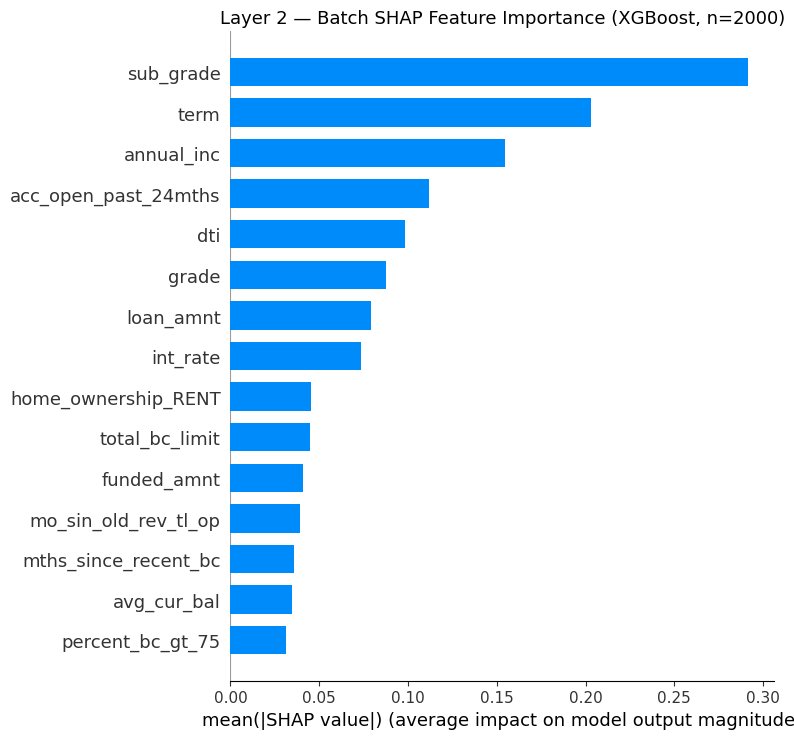

Saved: shap_bar_l2.png


In [11]:
shap.summary_plot(shap_values, X_shap_sample,
                  plot_type="bar", max_display=15, show=False)
plt.title("Layer 2 — Batch SHAP Feature Importance (XGBoost, n=2000)", fontsize=13)
plt.tight_layout()
plt.savefig('acrs_data/shap_bar_l2.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: shap_bar_l2.png")

In [13]:
def ks_stat(y, p): return ks_2samp(p[y==1], p[y==0]).statistic

auc_l2  = roc_auc_score(y_test_arr, ensemble_prob_test)
ks_l2   = ks_stat(y_test_arr, ensemble_prob_test)
gini_l2 = 2 * auc_l2 - 1
f1_l2   = f1_score(y_test_arr, (ensemble_prob_test >= 0.5).astype(int))

top_feature = importance_df.iloc[0]['feature']
top_shap    = round(float(importance_df.iloc[0]['mean_abs_shap']), 4)

print("=" * 60)
print("LAYER 2 RESULTS SUMMARY")
print("=" * 60)
print(f"  Predictive Performance (Ensemble, Test Set 2016+):")
print(f"    AUC-ROC  : {auc_l2:.4f}")
print(f"    KS Stat  : {ks_l2:.4f}")
print(f"    Gini     : {gini_l2:.4f}")
print(f"    F1 Score : {f1_l2:.4f}")
print(f"\n  Monitoring (Layer 2 additions):")
print(f"    PSI Ensemble     : {psi_ens:.4f}  → {psi_status(psi_ens)}")
print(f"    PSI XGBoost      : {psi_xgb:.4f}  → {psi_status(psi_xgb)}")
print(f"    PSI LightGBM     : {psi_lgbm:.4f}  → {psi_status(psi_lgbm)}")
print(f"    PSI RandomForest : {psi_rf:.4f}  → {psi_status(psi_rf)}")
print(f"\n  Explainability:")
print(f"    SHAP Top Feature : {top_feature} ({top_shap})")
print(f"    SHAP Sample Size : 2000 test loans")
print(f"\n  HITL Trigger     : PSI >= 0.10 Warning | >= 0.20 Alert")
print("=" * 60)

l2_results = {
    "layer": 2,
    "auc":  round(auc_l2, 4),
    "ks":   round(ks_l2, 4),
    "gini": round(gini_l2, 4),
    "f1":   round(f1_l2, 4),
    "psi_xgb":    round(psi_xgb, 4),
    "psi_lgbm":   round(psi_lgbm, 4),
    "psi_rf":     round(psi_rf, 4),
    "psi_ensemble": round(psi_ens, 4),
    "psi_status":   psi_status(psi_ens),
    "shap_top_feature": top_feature,
    "shap_top_value":   top_shap
}
with open('acrs_data/layer2_results.json', 'w') as f:
    json.dump(l2_results, f, indent=2)
print("Saved: layer2_results.json")
print("Layer 2 COMPLETE — Ready for Layer 3")

LAYER 2 RESULTS SUMMARY
  Predictive Performance (Ensemble, Test Set 2016+):
    AUC-ROC  : 0.7057
    KS Stat  : 0.2974
    Gini     : 0.4115
    F1 Score : 0.0345

  Monitoring (Layer 2 additions):
    PSI Ensemble     : 0.0038  → Stable
    PSI XGBoost      : 0.0051  → Stable
    PSI LightGBM     : 0.0051  → Stable
    PSI RandomForest : 0.0012  → Stable

  Explainability:
    SHAP Top Feature : sub_grade (0.2915)
    SHAP Sample Size : 2000 test loans

  HITL Trigger     : PSI >= 0.10 Warning | >= 0.20 Alert
Saved: layer2_results.json
Layer 2 COMPLETE — Ready for Layer 3
